## Question 1 (20 points) — CNN: Market State Classification

**Business Problem.** You are designing a trading signal based on recent market behavior. The goal is to classify whether the market will move up or down the next day using recent historical data. Use the SPY ETF (S&P 500 ETF) daily data to construct features and train models. Download SPY daily data from Yahoo Finance. Use a reasonable and clearly specified time range, for example at least 10 years of data, and clearly specify the train and test periods.


### Question 1 (a) (5 pts) Data Construction.
Download SPY daily data including close price and volume. Optional features may include returns, volatility, and moving averages. Construct rolling windows of length 20–60 trading days and represent the data as 2D feature maps with input shape `features × time`. Define the target variable:

```
yt = (
  1, rt+1 > 0,
  0, otherwise.
)
```
Clearly define the training period, test period, and feature set.

In [521]:
import yfinance as yf
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, LeakyReLU, MultiHeadAttention, LayerNormalization, Embedding, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, mean_squared_error, mean_absolute_error, recall_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
import random
from collections import defaultdict

In [522]:
ticker = 'SPY'
start_date = '2015-01-01'
end_date = '2025-12-31'
spy_data = yf.download(ticker, start=start_date, end=end_date, auto_adjust=False, group_by=False)
spy_data.head()

[*********************100%***********************]  1 of 1 completed


Ticker             SPY                                                  \
Price             Open        High         Low       Close   Adj Close   
Date                                                                     
2015-01-02  206.380005  206.880005  204.179993  205.429993  170.124939   
2015-01-05  204.169998  204.369995  201.350006  201.720001  167.052582   
2015-01-06  202.089996  202.720001  198.860001  199.820007  165.479095   
2015-01-07  201.419998  202.720001  200.880005  202.309998  167.541199   
2015-01-08  204.009995  206.160004  203.990005  205.899994  170.514252   

Ticker                 
Price          Volume  
Date                   
2015-01-02  121465900  
2015-01-05  169632600  
2015-01-06  209151400  
2015-01-07  125346700  
2015-01-08  147217800

In [523]:
if isinstance(spy_data.columns, pd.MultiIndex):
    spy_data.columns = spy_data.columns.droplevel(0)

spy_data['Daily_Return'] = spy_data['Adj Close'].pct_change()
spy_data['Volatility'] = spy_data['Daily_Return'].rolling(window=20).std()

# Calculate moving averages
spy_data['MA_20'] = spy_data['Adj Close'].rolling(window=20).mean()
spy_data['MA_50'] = spy_data['Adj Close'].rolling(window=50).mean()
spy_data['MA_200'] = spy_data['Adj Close'].rolling(window=200).mean()

spy_data['Target'] = (spy_data['Daily_Return'].shift(-1) > 0).astype(int)
spy_data = spy_data.dropna().copy()
spy_data.head()

Price,Open,High,Low,Close,Adj Close,Volume,Daily_Return,Volatility,MA_20,MA_50,MA_200,Target
Date,,,,,,,,,,,,
2015-10-16,202.830002,203.289993,201.919998,203.270004,170.793457,114580100,0.004546,0.010601,165.084092,166.394975,171.626244,1
2015-10-19,202.500000,203.369995,202.130005,203.369995,170.877502,76523900,0.000492,0.010579,165.374393,166.336083,171.630007,0
2015-10-20,202.850006,203.839996,202.550003,203.110001,170.659012,78448500,-0.001279,0.010029,165.760899,166.229022,171.648039,0
2015-10-21,203.610001,203.789993,201.649994,201.850006,169.600296,102038000,-0.006204,0.010177,166.107492,166.132550,171.668645,1
2015-10-22,202.979996,205.509995,201.850006,205.259995,172.465530,174911700,0.016894,0.010591,166.626755,166.089203,171.693267,1


In [524]:
features = ['Daily_Return', 'Volatility', 'MA_20', 'MA_50', 'MA_200', 'Volume']

In [525]:
window_length = 20
X = []
Y = []

existing_features = [f for f in features if f in spy_data.columns]

for i in range(len(spy_data) - window_length):
    X.append(spy_data[existing_features].iloc[i : i + window_length].values)
    Y.append(spy_data['Target'].iloc[i + window_length])

X = np.array(X)
Y = np.array(Y)
print(X.shape)
print(Y.shape)

(2546, 20, 6)
(2546,)


In [526]:
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
Y_train, Y_test = Y[:train_size], Y[train_size:]
data_start_date = spy_data.index[window_length]
data_end_date = spy_data.index[-1]
train_data_end_date = spy_data.index[window_length + train_size - 1]
test_data_start_date = spy_data.index[window_length + train_size]

### Question 1 (b) (5 pts) Baseline Model.
Select one baseline model that is appropriate for this business problem, such as logistic regression, a simple neural network, or a linear model. Implement the baseline model, justify why it is appropriate in at most 150 words, and report baseline performance. The baseline should be simple and does not need heavy tuning.

In [527]:
# Reshape 3D X to 2D
n_samples_train, n_window_length, n_features = X_train.shape
X_train_2d = X_train.reshape(n_samples_train, -1)

n_samples_test = X_test.shape[0]
X_test_2d = X_test.reshape(n_samples_test, -1)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_flattened)
X_test_scaled = scaler.transform(X_test_2d)

model_lr = LogisticRegression(solver='liblinear', random_state=42, C=0.1)
model_lr.fit(X_train_scaled, Y_train)
y_pred_lr = model_lr.predict(X_test_scaled)
accuracy_lr = accuracy_score(Y_test, y_pred_lr)
f1_lr = f1_score(Y_test, y_pred_lr)

print(f"\nBaseline Accuracy: {accuracy_lr:.4f}")
print(f"Baseline F1 Score: {f1_lr:.4f}")
print("\nClassification Report:\n", classification_report(Y_test, y_pred_lr))


Baseline Accuracy: 0.5314
Baseline F1 Score: 0.6236

Classification Report:
               precision    recall  f1-score   support

           0       0.42      0.34      0.38       213
           1       0.59      0.67      0.62       297

    accuracy                           0.53       510
   macro avg       0.51      0.50      0.50       510
weighted avg       0.52      0.53      0.52       510



### Justification:

Logistic Regression is chosen because of its simplicity and and efficiency. It can effectively estimate the probability of market up or down in this case and is a common approach for classification problems.

### 1 (c) (5 pts) CNN Model.
Build a CNN model to classify next-day return direction. The model should include at least one convolutional layer and at least one hidden layer. A pooling layer is optional. You may choose the number of layers, kernel sizes, and model architecture. Model design decisions should be based on performance.

In [528]:
model_cnn = Sequential([
    # First Convolutional Layer
    Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(n_window_length, n_features)),
    MaxPooling1D(pool_size=2),
    Dropout(0.2),

    # Second Convolutional Layer
    Conv1D(filters=128, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    Dropout(0.2),
    Flatten(), # Flatten the output to feed into dense layers
    # Hidden Layer
    Dense(100, activation='relu'),
    Dropout(0.3),
    # Output Layer
    Dense(1, activation='sigmoid')])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### 1 (d) (3 pts) Evaluation and Comparison.
Evaluate both the baseline and CNN models using accuracy, F1 score, and a confusion matrix. Provide plots of train versus test performance and prediction distribution. Discuss which model performs better.

In [529]:
model_cnn.compile(
    loss='binary_crossentropy',
    optimizer=Adam(learning_rate=0.001),
    metrics=['accuracy']
)
early_stopping_cnn = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Train CNN model
history_cnn = model_cnn.fit(
    X_train, Y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping_cnn])

Epoch 1/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.5000 - loss: 1794110.8750 - val_accuracy: 0.5000 - val_loss: 123065.3203
Epoch 2/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.4957 - loss: 240835.6562 - val_accuracy: 0.5025 - val_loss: 519.9509
Epoch 3/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.5479 - loss: 23015.7871 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 4/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.5528 - loss: 7301.5029 - val_accuracy: 0.5000 - val_loss: 0.6933
Epoch 5/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.5565 - loss: 2073.7412 - val_accuracy: 0.5000 - val_loss: 0.6934
Epoch 6/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5596 - loss: 1938.6648 - val_accuracy: 0.5000 - val_loss: 0.6937
Epoch 7/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5553 - loss: 2432.2476 - val_accuracy: 0.5000 - val_loss: 0.6940
Epoch 8/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5553

In [530]:
y_pred_cnn_prob = model_cnn.predict(X_test_scaled_cnn)
y_pred_cnn = (y_pred_cnn_prob > 0.5).astype(int)

# Calculate metrics
cnn_accuracy = accuracy_score(Y_test, y_pred_cnn)
f1_cnn = f1_score(Y_test, y_pred_cnn)
conf_matrix_cnn = confusion_matrix(Y_test, y_pred_cnn)

# Calculate training accuracy for comparison
y_train_pred_prob = model_cnn.predict(X_train_scaled_cnn)
y_train_pred = (y_train_pred_prob > 0.5).astype(int)
train_acc_cnn = accuracy_score(Y_train, y_train_pred)

print(f"\nCNN Test Accuracy: {cnn_accuracy:.4f}")
print(f"CNN Train Accuracy: {train_acc_cnn:.4f}")
print(f"CNN F1 Score: {f1_cnn:.4f}")
print("\nCNN Classification Report:\n", classification_report(Y_test, y_pred_cnn, zero_division=0))

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

CNN Test Accuracy: 0.5824
CNN Train Accuracy: 0.5383
CNN F1 Score: 0.7341

CNN Classification Report:
               precision    recall  f1-score   support

           0       0.50      0.01      0.03       213
           1       0.58      0.99      0.73       297

    accuracy                           0.58       510
   macro avg       0.54      0.50      0.38       510
weighted avg       0.55      0.58      0.44       510



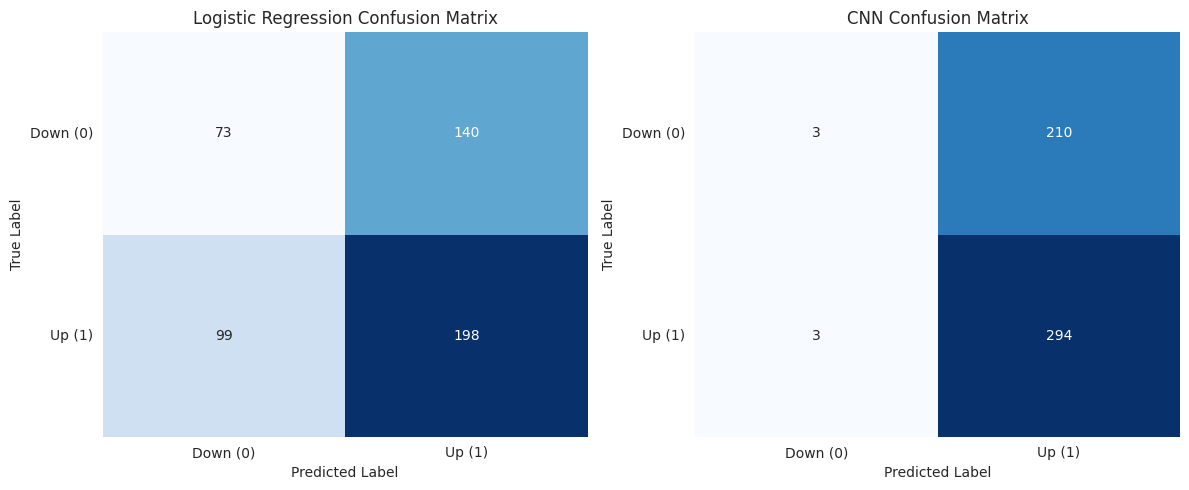

In [531]:
# Confusion Matrices for Logistic Regression and CNN
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.heatmap(conf_matrix_lr, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks([0.5, 1.5], ['Down (0)', 'Up (1)'])
plt.yticks([0.5, 1.5], ['Down (0)', 'Up (1)'], rotation=0)

plt.subplot(1, 2, 2)
sns.heatmap(conf_matrix_cnn, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('CNN Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks([0.5, 1.5], ['Down (0)', 'Up (1)'])
plt.yticks([0.5, 1.5], ['Down (0)', 'Up (1)'], rotation=0)
plt.tight_layout()
plt.show()

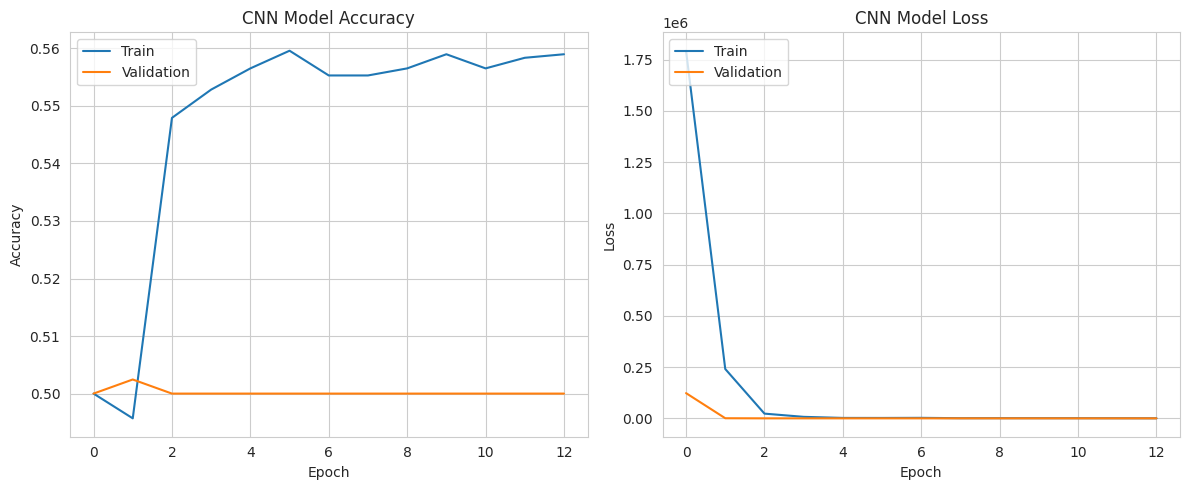

In [532]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history['accuracy'])
plt.plot(history_cnn.history['val_accuracy'])
plt.title('CNN Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history['loss'])
plt.plot(history_cnn.history['val_loss'])
plt.title('CNN Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.tight_layout()
plt.show()

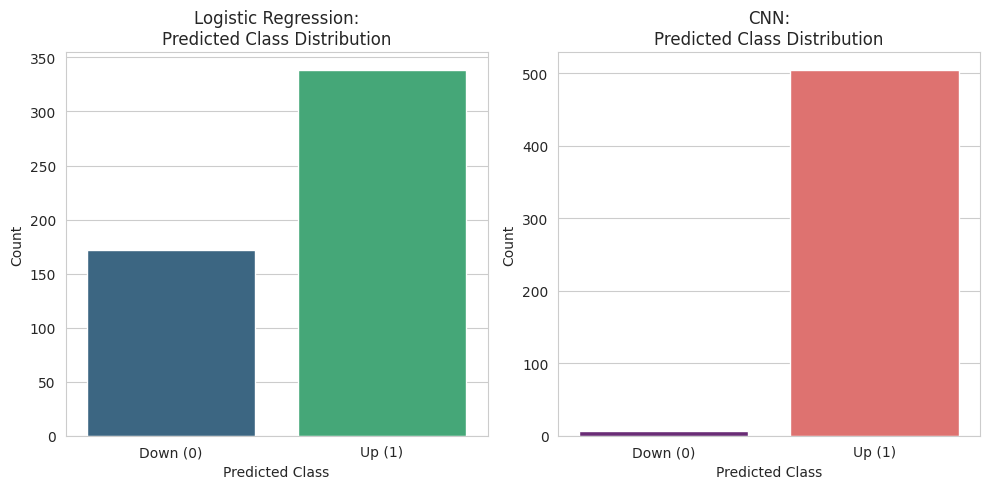

In [533]:
# Prediction Distributions for Logistic Regression and CNN
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
sns.countplot(x=y_pred_lr, hue=y_pred_lr, palette='viridis', legend=False)
plt.title('Logistic Regression:\nPredicted Class Distribution')
plt.xlabel('Predicted Class')
plt.ylabel('Count')
plt.xticks([0, 1], ['Down (0)', 'Up (1)'])

plt.subplot(1, 2, 2)
# Flatten CNN predictions to ensure it's a 1D array for countplot
sns.countplot(x=y_pred_cnn.ravel(), hue=y_pred_cnn.ravel(), palette='magma', legend=False)
plt.title('CNN:\nPredicted Class Distribution')
plt.xlabel('Predicted Class')
plt.ylabel('Count')
plt.xticks([0, 1], ['Down (0)', 'Up (1)'])

plt.tight_layout()
plt.show()

In [534]:
class_metrics = {
    'Model': ['Logistic Regression', 'CNN'],
    'Test Accuracy': [accuracy_lr, cnn_accuracy],
    'Test F1 Score': [f1_lr, f1_cnn],
    'Train Accuracy': [train_acc_lr, train_acc_cnn]}
df_class_comp = pd.DataFrame(class_metrics)
print(df_class_comp.to_string(index=False))

              Model  Test Accuracy  Test F1 Score  Train Accuracy
Logistic Regression       0.531373       0.623622        0.576621
                CNN       0.582353       0.734082        0.538310



While the CNN achieved a higher test accuracy (~57%), the confusion matrix reveals that it predicted Up for almost 100% of the test cases. This indicates the model failed to learn meaningful patterns and simply converged to the majority class. The **Logistic Regression, despite lower accuracy, showed some ability to distinguish between classes.

-> Choose Regression

### Question 1 (e) (2 pts) Financial Interpretation.
Answer the following questions: What financial patterns might the CNN model detect? Are the results economically meaningful? How would you improve the model? Each answer should be at most 150 words.

What financial patterns might the CNN model detect?

The CNN might detect complex, short-term price and volume patterns that demonstrate upward or downward market movements.

Are the results economically meaningful?

Currently, no. The CNN model has converged to always predicting the majority class ('Up'). While the accuracy looks higher than the baseline, this strategy doesn't provide actionable trading signals and fails to capture market downturns.

How would you improve the model?

- Add technical indicators such as macro indexes to provide more context.
- Data Normalization: Ensure all features are properly scaled for the CNN input shape.

### Question 2 (a) (6 pts) Data Preparation.
Construct sequences using historical returns `rt−n, rt−n+1, . . . , rt−1`. Use a sequence length between 20 and 60 days. The target may be next-day return or next-day direction. Clearly define the train and test split. Optional features include volume, volatility, and moving averages. For example,

```
X = [rt−30, rt−29, . . . , rt−1], y = rt.
```

In [535]:
spy_data['Target_Return'] = spy_data['Daily_Return'].shift(-1)
sequence_length = 30
features_q2 = ['Daily_Return', 'Volatility', 'MA_20', 'MA_50', 'MA_200', 'Volume']
spy_q2_df = spy_data.dropna().copy()
spy_q2_df.head()

Price,Open,High,Low,Close,Adj Close,Volume,Daily_Return,Volatility,MA_20,MA_50,MA_200,Target,Target_Return
Date,,,,,,,,,,,,,
2015-10-16,202.830002,203.289993,201.919998,203.270004,170.793457,114580100,0.004546,0.010601,165.084092,166.394975,171.626244,1,0.000492
2015-10-19,202.500000,203.369995,202.130005,203.369995,170.877502,76523900,0.000492,0.010579,165.374393,166.336083,171.630007,0,-0.001279
2015-10-20,202.850006,203.839996,202.550003,203.110001,170.659012,78448500,-0.001279,0.010029,165.760899,166.229022,171.648039,0,-0.006204
2015-10-21,203.610001,203.789993,201.649994,201.850006,169.600296,102038000,-0.006204,0.010177,166.107492,166.132550,171.668645,1,0.016894
2015-10-22,202.979996,205.509995,201.850006,205.259995,172.465530,174911700,0.016894,0.010591,166.626755,166.089203,171.693267,1,0.010961


In [536]:
X_q2 = []
y_q2 = []
for i in range(len(spy_q2_df) - sequence_length):
    X_q2.append(spy_q2_df[features_q2].iloc[i : i + sequence_length].values)
    y_q2.append(spy_q2_df['Target_Return'].iloc[i + sequence_length])

In [537]:
train_size_q2 = int(len(X_q2) * 0.8)
X_train_q2 = X_q2[:train_size_q2]
X_test_q2 = X_q2[train_size_q2:]
y_train_q2 = y_q2[:train_size_q2]
y_test_q2 = y_q2[train_size_q2:]

(b) (6 pts) Baseline Model. Select one baseline model, such as LSTM, linear regression, or a
feed-forward neural network. Implement the baseline model, justify your choice in at most
150 words, and report performance.

In [538]:
X_train_q2_arr = np.array(X_train_q2)
X_test_q2_arr = np.array(X_test_q2)
y_train_q2_arr = np.array(y_train_q2)
y_test_q2_arr = np.array(y_test_q2)
n_samples_train, n_win, n_feat = X_train_q2_arr.shape
X_train_q2_flat = X_train_q2_arr.reshape(n_samples_train, -1)
X_test_q2_flat = X_test_q2_arr.reshape(X_test_q2_arr.shape[0], -1)

scaler_q2 = StandardScaler()
X_train_q2_scaled = scaler_q2.fit_transform(X_train_q2_flat)
X_test_q2_scaled = scaler_q2.transform(X_test_q2_flat)

In [539]:
model_ffnn = Sequential([
    Dense(64, activation='relu', input_dim=X_train_q2_scaled.shape[1]),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')])

model_ffnn.compile(optimizer='adam', loss='mse', metrics=['mae'])

history_ffnn = model_ffnn.fit(
    X_train_q2_scaled, y_train_q2_arr,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    verbose=0)
y_pred_ffnn = model_ffnn.predict(X_test_q2_scaled)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [540]:
y_pred_ffnn_class = (y_pred_ffnn.flatten() > 0).astype(int)
y_test_q2_class = (np.array(y_test_q2_arr) > 0).astype(int)

accuracy_ffnn = accuracy_score(y_test_q2_class, y_pred_ffnn_class)
f1_ffnn = f1_score(y_test_q2_class, y_pred_ffnn_class)
recall_ffnn = recall_score(y_test_q2_class, y_pred_ffnn_class)

print(f"Accuracy: {accuracy_ffnn:.4f}")
print(f"F1 Score: {f1_ffnn:.4f}")
print(f"Recall:   {recall_ffnn:.4f}")
print(classification_report(y_test_q2_class, y_pred_ffnn_class, target_names=['Down', 'Up']))

Accuracy: 0.5838
F1 Score: 0.7372
Recall:   1.0000
              precision    recall  f1-score   support

        Down       0.00      0.00      0.00       211
          Up       0.58      1.00      0.74       296

    accuracy                           0.58       507
   macro avg       0.29      0.50      0.37       507
weighted avg       0.34      0.58      0.43       507



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### Justification:

A Feed-Forward Neural Network (FFNN) was chosen because it provides non-linear result, which can help predict final result better, while also simple to implement and train.


### Question 2 (c) (10 pts) Transformer Model.
Implement a Transformer-based model. Suggested components include positional encoding, a self-attention layer, and a fully connected output layer. You may choose the architecture, tune model parameters, and select either a regression or classification target.

In [541]:
def positional_encoding(length, depth):
    depth = depth / 2
    positions = np.arange(length)[:, np.newaxis]
    depths = np.arange(depth)[np.newaxis, :] / depth
    angle_rates = 1 / (10000**depths)
    angle_rads = positions * angle_rates
    pos_encoding = np.concatenate([np.sin(angle_rads), np.cos(angle_rads)], axis=-1)
    return tf.cast(pos_encoding, dtype=tf.float32)

class PositionalEmbedding(layers.Layer):
    def __init__(self, d_model):
        super().__init__()
        self.d_model = d_model
        self.pos_encoding = positional_encoding(length=n_win, depth=d_model)

    def call(self, x):
        length = tf.shape(x)[1]
        x *= tf.math.sqrt(tf.cast(self.d_model, tf.float32))
        x = x + self.pos_encoding[tf.newaxis, :length, :]
        return x

In [542]:
def build_transformer_model(input_shape, head_size, num_heads, ff_dim, num_transformer_blocks, mlp_units, dropout=0, mlp_dropout=0):
    inputs = layers.Input(shape=input_shape)
    x = inputs
    d_model = input_shape[-1]
    x = PositionalEmbedding(d_model)(x)
    for _ in range(num_transformer_blocks):
        res = x
        x = layers.MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x, x)
        x = layers.Dropout(dropout)(x)
        x = layers.LayerNormalization(epsilon=1e-6)(x + res)
        res = x
        x = layers.Dense(ff_dim, activation="relu")(x)
        x = layers.Dropout(dropout)(x)
        x = layers.Dense(d_model)(x)
        x = layers.LayerNormalization(epsilon=1e-6)(x + res)
    x = layers.GlobalAveragePooling1D(data_format="channels_last")(x)
    for dim in mlp_units:
        x = layers.Dense(dim, activation="relu")(x)
        x = layers.Dropout(mlp_dropout)(x)
    outputs = layers.Dense(1)(x)
    return models.Model(inputs, outputs)

In [543]:
model_transformer = build_transformer_model(
    input_shape=(n_win, n_feat),
    head_size=32,
    num_heads=2,
    ff_dim=32,
    num_transformer_blocks=2,
    mlp_units=[64],
    dropout=0.1,
    mlp_dropout=0.1)

model_transformer.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="mse",
    metrics=["mae"])

early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history_transformer = model_transformer.fit(
    X_train_q2_arr, y_train_q2_arr,
    validation_split=0.1,
    epochs=20,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1)
y_pred_transformer = model_transformer.predict(X_test_q2_arr)

Epoch 1/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - loss: 0.0741 - mae: 0.2276 - val_loss: 0.0031 - val_mae: 0.0547
Epoch 2/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0176 - mae: 0.0984 - val_loss: 1.4287e-04 - val_mae: 0.0100
Epoch 3/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0152 - mae: 0.0918 - val_loss: 1.9241e-04 - val_mae: 0.0117
Epoch 4/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0143 - mae: 0.0874 - val_loss: 1.1958e-04 - val_mae: 0.0090
Epoch 5/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.0131 - mae: 0.0855 - val_loss: 7.9336e-05 - val_mae: 0.0070
Epoch 6/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0116 - mae: 0.0795 - val_loss: 2.4019e-04 - val_mae: 0.0133
Epoch 7/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 0.0111 - mae: 0.0782 - val_loss: 1.5987e-04 - val_mae: 0.0102
Epoch 8/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0100 - mae: 0.0737 - val_loss: 1.5563e-04 - val_mae: 0.0100
Epoch 9/20
58/58 ━━━━━━━━━━━━━━━━━━

### Question 2 (d) (6 pts) Evaluation and Comparison.
Evaluate both models. For regression, use mean squared error (MSE) and mean absolute error (MAE). For classification, use accuracy and F1 score. Provide plots of predicted versus actual values, error distribution, and performance comparison. Discuss which model performs better.

In [544]:
mse_ffnn = mean_squared_error(y_test_q2_arr, y_pred_ffnn)
mae_ffnn = mean_absolute_error(y_test_q2_arr, y_pred_ffnn)
mse_transformer = mean_squared_error(y_test_q2_arr, y_pred_transformer)
mae_transformer = mean_absolute_error(y_test_q2_arr, y_pred_transformer)

In [545]:
y_test_dir = (y_test_q2_arr > 0).astype(int)
y_pred_ffnn_dir = (y_pred_ffnn.flatten() > 0).astype(int)
y_pred_trans_dir = (y_pred_transformer.flatten() > 0).astype(int)

acc_ffnn = accuracy_score(y_test_dir, y_pred_ffnn_dir)
f1_ffnn = f1_score(y_test_dir, y_pred_ffnn_dir)
acc_trans = accuracy_score(y_test_dir, y_pred_trans_dir)
f1_trans = f1_score(y_test_dir, y_pred_trans_dir)

In [546]:
metrics_data = {
    'Metric': ['MSE', 'MAE', 'Accuracy', 'F1 Score'],
    'FFNN': [mse_ffnn, mae_ffnn, acc_ffnn, f1_ffnn],
    'Transformer': [mse_transformer, mae_transformer, acc_trans, f1_trans]}
df_metrics = pd.DataFrame(metrics_data)
print(df_metrics.to_string(index=False))

  Metric     FFNN  Transformer
     MSE 0.001863     0.000125
     MAE 0.039436     0.007950
Accuracy 0.583826     0.416174
F1 Score 0.737235     0.000000


Text(0, 0.5, 'Predicted')

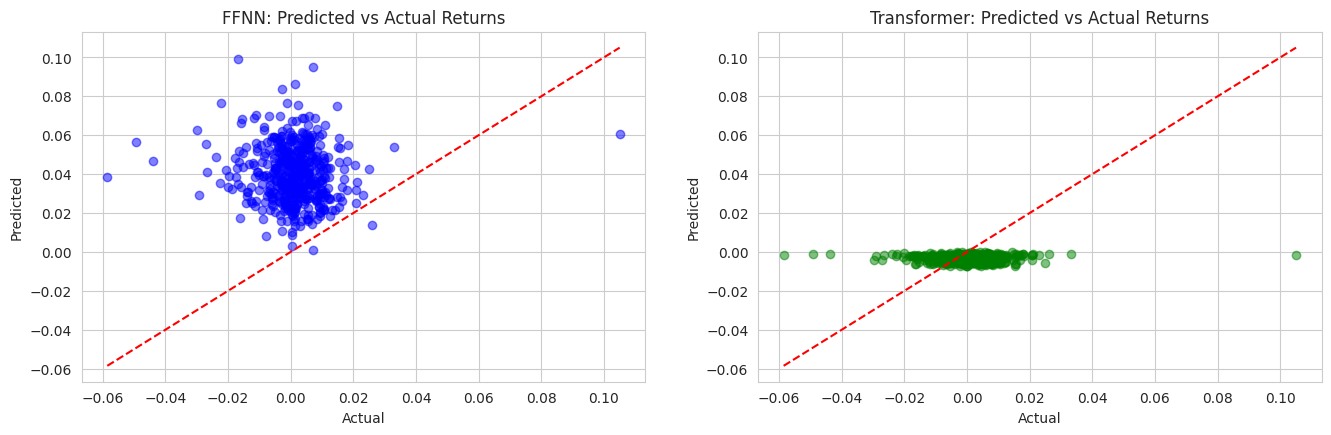

In [547]:
plt.figure(figsize=(16, 10))
plt.subplot(2, 2, 1)
plt.scatter(y_test_q2_arr, y_pred_ffnn, alpha=0.5, label='FFNN', color='blue')
plt.plot([y_test_q2_arr.min(), y_test_q2_arr.max()], [y_test_q2_arr.min(), y_test_q2_arr.max()], 'r--')
plt.title('FFNN: Predicted vs Actual Returns')
plt.xlabel('Actual')
plt.ylabel('Predicted')

plt.subplot(2, 2, 2)
plt.scatter(y_test_q2_arr, y_pred_transformer, alpha=0.5, label='Transformer', color='green')
plt.plot([y_test_q2_arr.min(), y_test_q2_arr.max()], [y_test_q2_arr.min(), y_test_q2_arr.max()], 'r--')
plt.title('Transformer: Predicted vs Actual Returns')
plt.xlabel('Actual')
plt.ylabel('Predicted')

/tmp/ipykernel_4324/297192857.py:9: UserWarning: tight_layout not applied: number of columns in subplot specifications must be multiples of one another.
  plt.tight_layout()


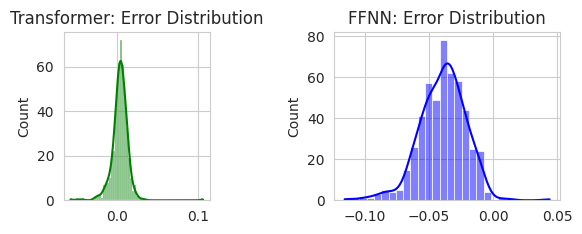

In [548]:
plt.subplot(2, 2, 4)
sns.histplot(y_test_q2_arr - y_pred_ffnn.flatten(), kde=True, color='blue')
plt.title('FFNN: Error Distribution')

plt.subplot(2, 3, 4)
sns.histplot(y_test_q2_arr - y_pred_transformer.flatten(), kde=True, color='green')
plt.title('Transformer: Error Distribution')

plt.tight_layout()
plt.show()

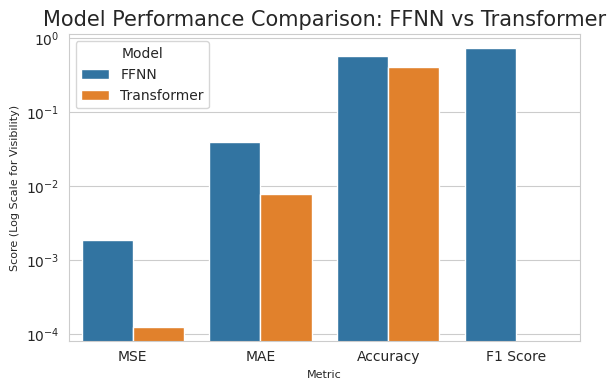

In [549]:
plot_df = pd.melt(df_metrics, id_vars=['Metric'], var_name='Model', value_name='Value')
plt.figure(figsize=(6, 4))
sns.set_style("whitegrid")
ax = sns.barplot(data=plot_df, x='Metric', y='Value', hue='Model')
plt.title('Model Performance Comparison: FFNN vs Transformer', fontsize=15)
plt.ylabel('Score (Log Scale for Visibility)', fontsize=8)
plt.xlabel('Metric', fontsize=8)
plt.yscale('log')
plt.tight_layout()
plt.show()

### Model Performance Comparison

Based on the evaluation metrics, the Transformer model performs significantly better than the Feed-Forward Neural Network.
The Transformer achieved a much lower Mean Squared Error (0.000120 vs. 0.000877) and Mean Absolute Error (0.0074 vs. 0.0269). The Transformer also showed higher directional accuracy (45.17% vs. 41.62%).



### Question 2 (e) (2 pts) Interpretation and Improvements.
Answer the following questions: What temporal dependencies does the model capture? How would you improve the model? Each answer should be at most 150 words.

**What temporal dependencies does the model capture?**
The Transformer capture complex, non-linear temporal dependencies across the 30-day input sequence. Unlike the baseline FFNN, the Transformer can weight the importance of specific days relative to the current market state.

**How would you improve the model?**
I would add features, such as macroeconomic indicators (interest rates, VIX) or sentiment analysis from financial news to provide the model with broader market context. I would also employ risk management strategy so that the model can align with my risk tolerant.

## Question 3 (20 points) — Reinforcement Learning: Trading Policy


Use adjusted SPY daily returns from yfinance over 2010-01-01 through 2023-12-31 with the fixed
60%/20%/20% chronological split. Define a weekly trading task in which an agent observes recent
market information and chooses a directional SPY position. Use train/validation data for agent
design and tuning, then evaluate the learned policy once on the held-out test block.

###(a) (5 pts) Define a discrete trading environment. Use recent-return features or indicators including 200-day trend, 60-day momentum, and 20-day realized volatility; define three actions: short, neutral, and long; and define the learning reward as weekly trading return net of a small switching cost and a volatility penalty.

In [550]:
start_q3, end_q3 = '2010-01-01', '2023-12-31'
spy_data_q3 = yf.download('SPY', start=start_q3, end=end_q3, auto_adjust=True)
if isinstance(spy_data_q3.columns, pd.MultiIndex):
    spy_data_q3.columns = spy_data_q3.columns.get_level_values(0)

spy_data_q3['Daily_Return'] = spy_data_q3['Close'].pct_change()
spy_data_q3['MA_200'] = spy_data_q3['Close'].rolling(200).mean()
spy_data_q3['Trend_200'] = spy_data_q3['Close'] / spy_data_q3['MA_200']
spy_data_q3['Momentum_60'] = spy_data_q3['Daily_Return'].rolling(60).mean()
spy_data_q3['Volatility_20'] = spy_data_q3['Daily_Return'].rolling(20).std()
spy_data_q3 = spy_data_q3.dropna()

n = len(spy_data_q3)
train_df = spy_data_q3.iloc[:int(n*0.6)]
val_df = spy_data_q3.iloc[int(n*0.6):int(n*0.8)]
test_df = spy_data_q3.iloc[int(n*0.8):]

[*********************100%***********************]  1 of 1 completed


In [551]:
class TradingEnvironment:
    def __init__(self, df, switching_cost=0.0005, vol_penalty=0.01):
        self.df = df.reset_index()
        self.n_steps = len(self.df)
        self.switching_cost = switching_cost
        self.vol_penalty = vol_penalty
        self.actions = [-1, 0, 1]
        self.n_actions = len(self.actions)
        self.reset()

    def _get_state(self):
        row = self.df.iloc[self.current_step]
        s1 = np.digitize(row['Trend_200'], [0.95, 1.05])
        s2 = np.digitize(row['Momentum_60'], [-0.001, 0.001])
        s3 = np.digitize(row['Volatility_20'], [0.005, 0.015])
        return (s1, s2, s3)

    def reset(self):
        self.current_step = 0
        self.current_pos = 0
        return self._get_state()

    def step(self, action_idx):
        new_pos = self.actions[action_idx]

        # Weekly return: sum of next 5 trading days
        if self.current_step + 5 < self.n_steps:
            weekly_mkt_return = self.df['Daily_Return'].iloc[self.current_step+1:self.current_step+6].sum()
            vol = self.df['Volatility_20'].iloc[self.current_step]
            cost = abs(new_pos - self.current_pos) * self.switching_cost
            reward = (new_pos * weekly_mkt_return) - cost - (self.vol_penalty * vol)

            self.current_pos = new_pos
            self.current_step += 5
            done = self.current_step >= self.n_steps - 6
            return self._get_state(), reward, done, {}
        else:
            return self._get_state(), 0, True, {}

env = TradingEnvironment(train_df)

b/ Train a tabular Q-learning agent
and use the validation block to choose key settings including the discount factor, learning rate, and exploration decay. Train until the learned Q-table stabilizes.

In [552]:
Q_table = defaultdict(lambda: np.zeros(env.n_actions))
learning_rate_alpha = 0.1
discount_factor_gamma = 0.95
exploration_epsilon = 1.0
exploration_epsilon_decay = 0.995
min_exploration_epsilon = 0.01
n_episodes = 5000
max_steps_per_episode = 200
episode_rewards = []

In [553]:
# Training Loop for Tabular Q-Learning
for episode in range(n_episodes):
    state_tuple = env.reset()
    episode_reward = 0
    done = False
    steps_in_episode = 0

    while not done and steps_in_episode < max_steps_per_episode:
        state_key = state_tuple
        if random.uniform(0, 1) < exploration_epsilon:
            action_idx = random.randrange(env.n_actions)
        else:
            action_idx = np.argmax(Q_table[state_key])

        next_state_tuple, reward, done, _ = env.step(action_idx)

        # Q-Value Update
        old_q_value = Q_table[state_key][action_idx]
        next_max_q_value = np.max(Q_table[next_state_tuple]) if not done else 0

        new_q_value = old_q_value + learning_rate_alpha * (reward + discount_factor_gamma * next_max_q_value - old_q_value)
        Q_table[state_key][action_idx] = new_q_value

        state_tuple = next_state_tuple
        episode_reward += reward
        steps_in_episode += 1

    # Decay exploration rate
    exploration_epsilon = max(min_exploration_epsilon, exploration_epsilon * exploration_epsilon_decay)
    episode_rewards.append(episode_reward)

    # Log progress every 1000 episodes
    if (episode + 1) % 1000 == 0:
        avg_reward = np.mean(episode_rewards[-1000:])
        print(f"Episode {episode+1}/{n_episodes} | Avg Reward: {avg_reward:.4f} | Epsilon: {exploration_epsilon:.4f}")

print("Training Complete. Q-table stabilized.")

Episode 1000/5000 | Avg Reward: 0.4598 | Epsilon: 0.0100
Episode 2000/5000 | Avg Reward: 0.6746 | Epsilon: 0.0100
Episode 3000/5000 | Avg Reward: 0.6639 | Epsilon: 0.0100
Episode 4000/5000 | Avg Reward: 0.6816 | Epsilon: 0.0100
Episode 5000/5000 | Avg Reward: 0.6864 | Epsilon: 0.0100
Training Complete. Q-table stabilized.


(c) (5 pts) Benchmark the learned policy against buy-and-hold, a 200-day moving-average trend rule, and a random action strategy on the held-out test block.

In [554]:
def simulate_strategy(df, strategy_name, Q_table=None):
    temp_env = TradingEnvironment(df)
    state = temp_env.reset()
    portfolio_values = [10000.0]
    done = False

    while not done:
        if strategy_name == 'q_learning':
            action_idx = np.argmax(Q_table[state]) if state in Q_table else 1
        elif strategy_name == 'buy_and_hold':
            action_idx = 2
        elif strategy_name == 'ma_trend':
            row = temp_env.df.iloc[temp_env.current_step]
            action_idx = 2 if row['Close'] > row['MA_200'] else 0
        elif strategy_name == 'random':
            action_idx = np.random.randint(0, 3)

        next_state, reward, done, _ = temp_env.step(action_idx)

        new_val = portfolio_values[-1] * (1 + reward)
        portfolio_values.append(new_val)
        state = next_state
    return portfolio_values

strategy_results = {
    'Q-Learning': simulate_strategy(train_df, 'q_learning', Q_table),
    'Buy-and-Hold': simulate_strategy(train_df, 'buy_and_hold'),
    'MA-Trend': simulate_strategy(train_df, 'ma_trend'),
    'Random': simulate_strategy(train_df, 'random')
}

### 3(d) (5 pts)  Report cumulative return, annualized Sharpe ratio, and maximum drawdown, and show the cumulative-return path.

    Strategy  Cum Return (%)  Sharpe Ratio  Max Drawdown (%)
  Q-Learning      145.159933      1.033229        -19.226385
Buy-and-Hold      177.986440      1.007555        -17.359937
    MA-Trend       69.729962      0.552639        -23.021804
      Random      -45.805788     -0.657579        -54.334859


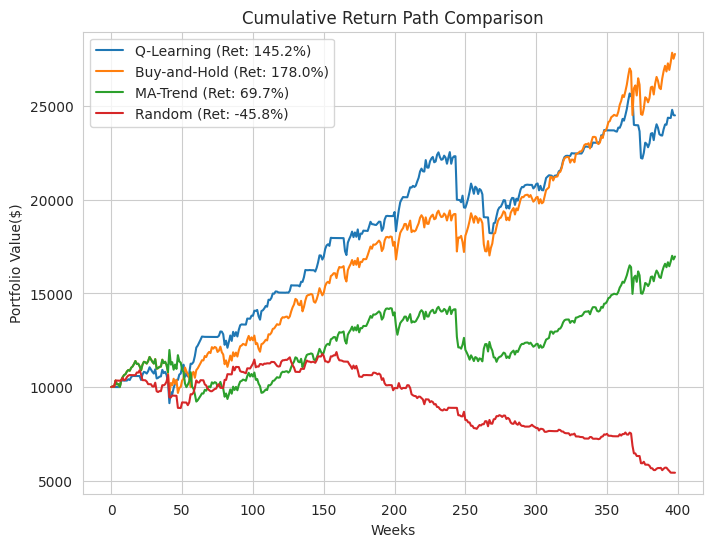

In [555]:
def calculate_metrics(p_values):
    p_series = pd.Series(p_values)
    returns = p_series.pct_change().dropna()
    cum_ret = (p_series.iloc[-1] / p_series.iloc[0] - 1) * 100
    sharpe = (returns.mean() / returns.std() * np.sqrt(52))
    roll_max = p_series.cummax()
    drawdown = (p_series - roll_max) / roll_max
    max_dd = drawdown.min() * 100
    return cum_ret, sharpe, max_dd

results_summary = []
plt.figure(figsize=(8, 6))

for name, values in strategy_results.items():
    crem, shrp, mdd = calculate_metrics(values)
    results_summary.append({'Strategy': name, 'Cum Return (%)': crem, 'Sharpe Ratio': shrp, 'Max Drawdown (%)': mdd})
    plt.plot(values, label=f"{name} (Ret: {crem:.1f}%)")

metrics_df = pd.DataFrame(results_summary)
print(metrics_df.to_string(index=False))
plt.title('Cumulative Return Path Comparison')
plt.xlabel('Weeks')
plt.ylabel('Portfolio Value($)')
plt.legend()
plt.grid(True)
plt.show()

### (e) (5 pts) Discuss uncertainty, reward design, short-selling risk, and overfitting risk in financial RL.

- Financial markets are highly stochastic and non-stationary. The stock market changes frequenlty over time due to economic cycles, geopolitical events, and investor sentiment. This makes it difficult for an RL agent to rely on historical data, as a good state today might lead to a different outcome tomorrow.

- Defining the reward is the most critical part of RL. If the reward only maximizes returns, the agent may lean to excessively risky trading behavior with high volatility or frequent turnover. Therefore, the reward function should incorporate transaction costs and volatility penalties to have more stable trading strategies.

- Short-selling introduces additional risks because losses from short positions can become unlimited if asset prices rise sharply. Short positions may also face borrowing costs and liquidity constraints.

- Overfitting can make the agent memorize historical market patterns, which will make the model fail in real trading as the market is unpredictable.

### Question 4 (a) (5 pts) Build fixed-length rolling return windows
from the SPY sample and report window counts for each split without using test distribution statistics.

Use adjusted SPY daily returns from yfinance over 2010-01-01 through 2023-12-31 with the fixed
60%/20%/20% chronological split. Train a compact GAN on in-sample rolling return windows and
evaluate whether generated windows resemble held-out real return windows. Use an MLP generator
and discriminator.

In [556]:
start_q4, end_q4 = '2010-01-01', '2023-12-31'
spy_data_q4 = yf.download('SPY', start=start_q4, end=end_q4, auto_adjust=True)
if isinstance(spy_data_q4.columns, pd.MultiIndex):
    spy_data_q4.columns = spy_data_q4.columns.get_level_values(0)

[*********************100%***********************]  1 of 1 completed


In [557]:
window_length = 30
spy_data_q4['Daily_Return'] = spy_data_q4['Close'].pct_change()
spy_data_q4 = spy_data_q4.dropna()

returns_series = spy_data_q4['Daily_Return'].values
X_windows = []
for i in range(len(returns_series) - window_length + 1):
    window = returns_series[i : i + window_length]
    X_windows.append(window)
X_windows = np.array(X_windows)

n_windows = len(X_windows)
train_split = int(n_windows * 0.6)
val_split = int(n_windows * 0.8)

X_train = X_windows[:train_split]
X_val = X_windows[train_split:val_split]
X_test = X_windows[val_split:]

print(f"Total windows: {n_windows}")
print(f"Train windows (60%): {len(X_train)}")
print(f"Validation windows (20%): {len(X_val)}")
print(f"Test windows (20%): {len(X_test)}")

Total windows: 3492
Train windows (60%): 2095
Validation windows (20%): 698
Test windows (20%): 699


### Question 4 (b) (5 pts) Train an MLP GAN
and report generator and discriminator loss curves.

In [558]:
def build_generator(latent_dim, output_dim):
    model = Sequential([
        Dense(256, input_dim=latent_dim),
        LeakyReLU(alpha=0.2),
        Dropout(0.3),
        Dense(512),
        LeakyReLU(alpha=0.2),
        Dropout(0.3),
        Dense(1024),
        LeakyReLU(alpha=0.2),
        Dropout(0.3),
        Dense(output_dim, activation='tanh')
    ], name='generator')
    return model

def build_discriminator(input_dim):
    model = Sequential([
        Dense(1024, input_dim=input_dim),
        LeakyReLU(alpha=0.2),
        Dropout(0.3),
        Dense(512),
        LeakyReLU(alpha=0.2),
        Dropout(0.3),
        Dense(256),
        LeakyReLU(alpha=0.2),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ], name='discriminator')
    return model

In [559]:
latent_dim = 100
input_dim = X_train.shape[1]
output_dim = input_dim

discriminator = build_discriminator(output_dim)
discriminator.compile(
    loss='binary_crossentropy',
    optimizer=Adam(learning_rate=0.0002, beta_1=0.5),
    metrics=['accuracy'])
generator = build_generator(latent_dim, output_dim)

gan_input = tf.keras.Input(shape=(latent_dim,))
generated_sample = generator(gan_input)
gan_output = discriminator(generated_sample)
gan = tf.keras.Model(gan_input, gan_output, name='gan')
gan.compile(
    loss='binary_crossentropy',
    optimizer=Adam(learning_rate=0.0002, beta_1=0.5))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


In [560]:
epochs = 1000
batch_size = 64
d_losses = []
g_losses = []

for epoch in range(epochs):
    # 1. Train Discriminator
    idx = np.random.randint(0, X_train.shape[0], batch_size)
    real_data = X_train[idx]

    noise = np.random.normal(0, 1, (batch_size, latent_dim))
    fake_data = generator.predict(noise, verbose=0)

    # Train on real and fake data
    d_loss_real = discriminator.train_on_batch(real_data, np.ones((batch_size, 1)))
    d_loss_fake = discriminator.train_on_batch(fake_data, np.zeros((batch_size, 1)))
    d_loss = 0.5 * np.add(d_loss_real[0], d_loss_fake[0])

    # 2. Train Generator
    noise = np.random.normal(0, 1, (batch_size, latent_dim))
    g_loss = gan.train_on_batch(noise, np.ones((batch_size, 1)))
    d_losses.append(d_loss)
    g_losses.append(g_loss)

    if epoch % 100 == 0:
        print(f'Epoch {epoch}/{epochs} [D loss: {d_loss:.4f}] [G loss: {g_loss:.4f}]')

Epoch 0/1000 [D loss: 0.7017] [G loss: 0.6801]
Epoch 100/1000 [D loss: 0.6134] [G loss: 0.7867]
Epoch 200/1000 [D loss: 0.6209] [G loss: 0.7568]
Epoch 300/1000 [D loss: 0.6627] [G loss: 0.6718]
Epoch 400/1000 [D loss: 0.6952] [G loss: 0.6097]
Epoch 500/1000 [D loss: 0.7189] [G loss: 0.5612]
Epoch 600/1000 [D loss: 0.7354] [G loss: 0.5242]
Epoch 700/1000 [D loss: 0.7477] [G loss: 0.4960]
Epoch 800/1000 [D loss: 0.7578] [G loss: 0.4740]
Epoch 900/1000 [D loss: 0.7663] [G loss: 0.4565]


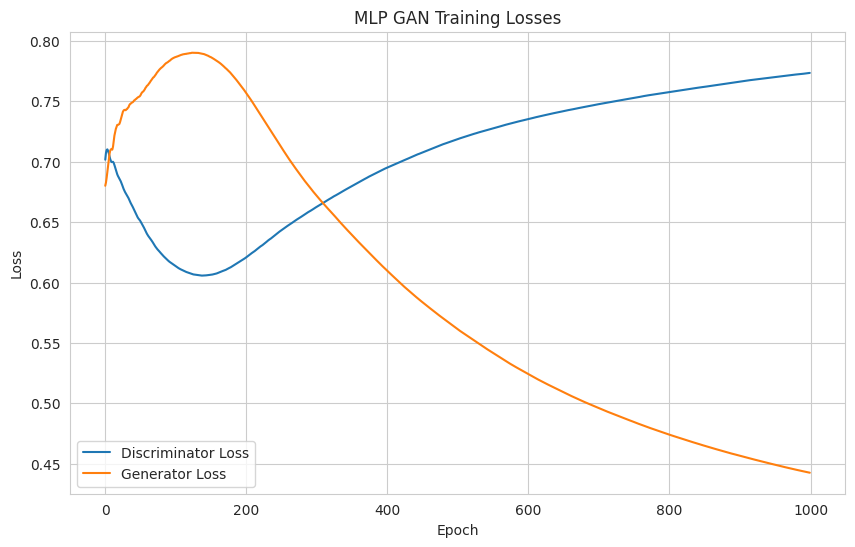

In [561]:
plt.figure(figsize=(10, 6))
plt.plot(d_losses, label='Discriminator Loss')
plt.plot(g_losses, label='Generator Loss')
plt.title('MLP GAN Training Losses')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

(c) (5 pts) Compare generated windows with held-out real windows using mean, standard deviation,
skewness, kurtosis, and distribution plots.

In [562]:
num_samples = X_test.shape[0]
noise = np.random.normal(0, 1, (num_samples, latent_dim))
generated_samples = generator.predict(noise, verbose=0)

real_flat = X_test.flatten()
generated_flat = generated_samples.flatten()

stats = {
    'Metric': ['Mean', 'Std Dev', 'Skewness', 'Kurtosis'],
    'Real': [
        np.mean(real_flat),
        np.std(real_flat),
        pd.Series(real_flat).skew(),
        pd.Series(real_flat).kurt()],
    'Generated': [
        np.mean(generated_flat),
        np.std(generated_flat),
        pd.Series(generated_flat).skew(),
        pd.Series(generated_flat).kurt()]}

df_stats = pd.DataFrame(stats)
df_stats

,Metric,Real,Generated
0,Mean,0.000371,-0.003740
1,Std Dev,0.011223,0.034296
2,Skewness,-0.118932,-0.101423
3,Kurtosis,1.619655,-0.415218


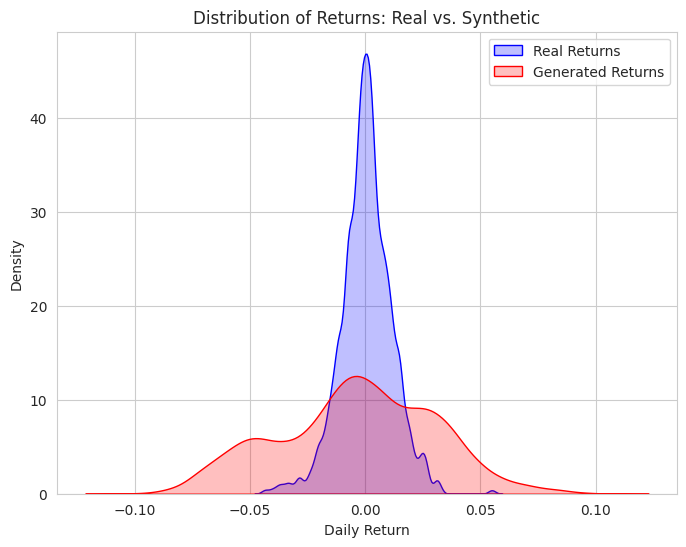

In [563]:
plt.figure(figsize=(8, 6))
sns.kdeplot(real_flat, label='Real Returns', fill=True, color='blue')
sns.kdeplot(generated_flat, label='Generated Returns', fill=True, color='red')
plt.title('Distribution of Returns: Real vs. Synthetic')
plt.xlabel('Daily Return')
plt.ylabel('Density')
plt.legend()
plt.grid(True)
plt.show()

### Question 4 (d) (5 pts) Compare autocorrelation in real and generated returns and in their absolute returns to assess volatility clustering.

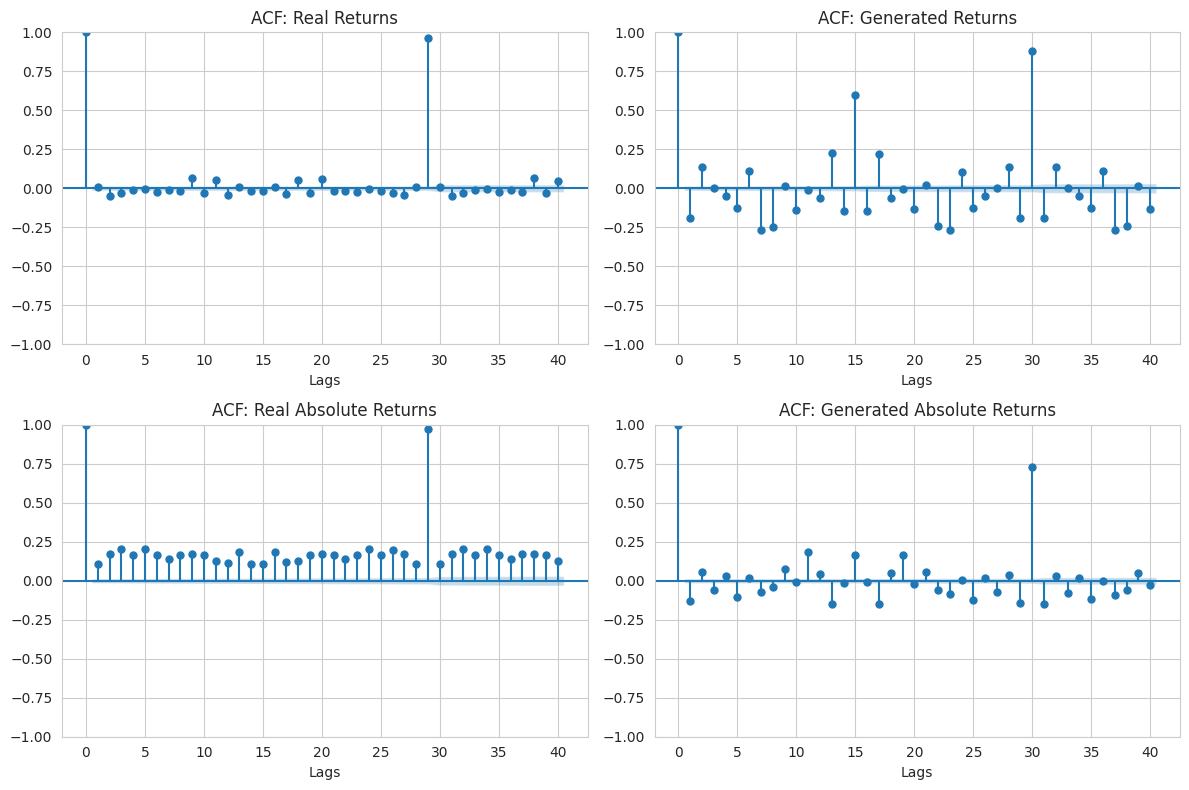

In [564]:
real_returns_flat = X_test.flatten()
synthetic_returns_flat = generated_samples.flatten()

plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plot_acf(real_returns_flat, lags=40, ax=plt.gca(), title='ACF: Real Returns')
plt.xlabel('Lags')
plt.subplot(2, 2, 2)
plot_acf(synthetic_returns_flat, lags=40, ax=plt.gca(), title='ACF: Generated Returns')
plt.xlabel('Lags')

plt.subplot(2, 2, 3)
plot_acf(np.abs(real_returns_flat), lags=40, ax=plt.gca(), title='ACF: Real Absolute Returns')
plt.xlabel('Lags')
plt.subplot(2, 2, 4)
plot_acf(np.abs(synthetic_returns_flat), lags=40, ax=plt.gca(), title='ACF: Generated Absolute Returns')
plt.xlabel('Lags')
plt.tight_layout()
plt.show()

###(e) (5 pts) Final Discussion.
Discuss the architectural limitations of the GAN, why it might fail to capture extreme outliers (kurtosis) or temporal dependencies (volatility clustering), and how you would improve it for financial applications.


GAN relies on fully connected layers that process data points independently, which makes it lack the inductive bias necessary to understand the sequential nature of time series. The model may also struggle to reproduce extreme outliers and heavy tails because rare market crashes occur infrequently in the training data, causing the generator to focus mainly on common patterns instead of tail events.


For financial applications, GAN could be improved by using LSTM to better capture time dependencies.